## **Load Libraries**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.listdir()

['input-20261002T185251Z-1-001.zip',
 'input1',
 'resources',
 'Task.ipynb',
 'TestFile.py']

## **Read Data**

In [2]:
folder_path = "input1"

In [3]:
def read_files(folder_path):

    signals = {}
    files = os.listdir(folder_path)

    for file_name in files: 

        if file_name.endswith(".txt"):
            file_path = os.path.join(folder_path, file_name)
            indices = []
            samples = []

            with open(file_path, "r") as file:

                # Skip the first two lines (zeroes lines)
                file.readline()
                file.readline()

                num_samples = int(file.readline().strip())

                for i in range(num_samples):

                    line = file.readline().strip()
                    parts = line.split()

                    index = int(parts[0])
                    sample = float(parts[1])

                    indices.append(index)
                    samples.append(sample)

            signal_name = os.path.splitext(file_name)[0]

            # Store the signal in dictionary
            signals[signal_name] = {
                "indices": indices,
                "samples": samples
            }

    return signals

In [4]:
signals = read_files(folder_path)

In [5]:
print (signals.keys())

dict_keys(['Signal1', 'Signal2', 'signal3'])


## **Display Functions**

### Display continuous 

In [6]:
def dis_cont(signal_name, signals):
    indices = signals[signal_name]["indices"]
    samples = signals[signal_name]["samples"]

    plt.plot(indices, samples)
    plt.xlabel("Index")
    plt.ylabel("Amplitude")
    plt.title(f"Signal: {signal_name}")
    plt.show()
    return

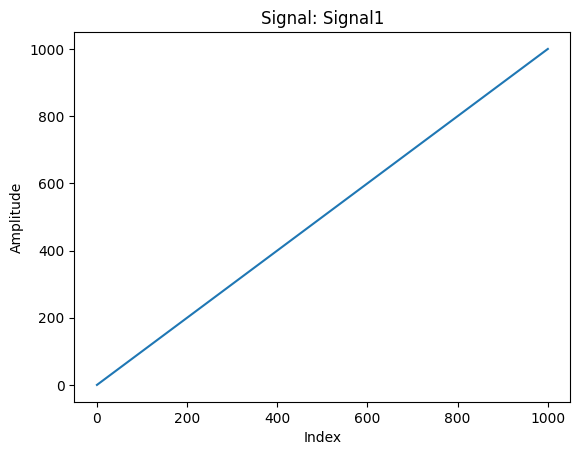

In [7]:
dis_cont("Signal1", signals)

### Display Discrete

In [13]:
def dis_dicrete(signal_name , signals):

    indices = signals[signal_name]["indices"]
    samples = signals[signal_name]["samples"]

    plt.figure(figsize=(10, 6))
    plt.stem(indices, samples)

    plt.xlabel("Index")
    plt.ylabel("Signlal Value")
    plt.title(f"Signal: {signal_name}")
    plt.show()
    return


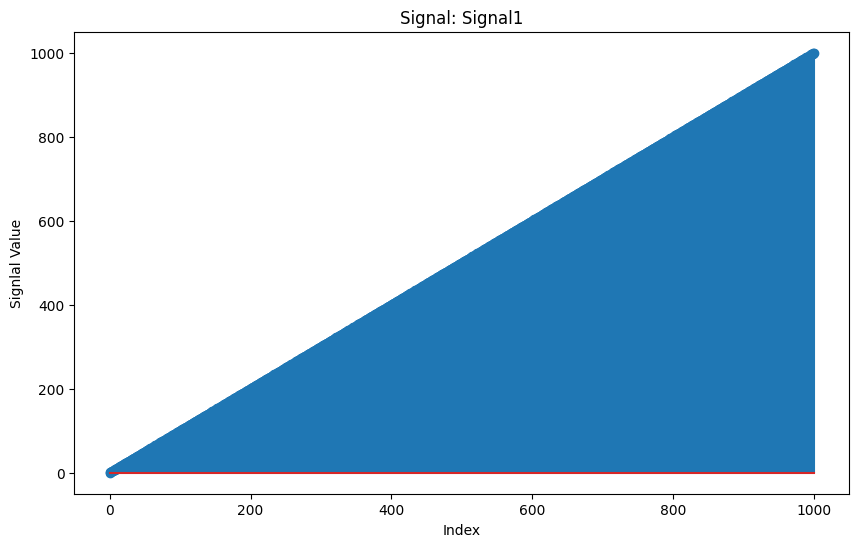

In [14]:
dis_dicrete("Signal1", signals)

---


## **Math operations**

### Addition Function

In [10]:
def add_signals(signals , signal_names):

    result_indices = signals[signal_names[0]]['indices'].copy()
    result_samples = [0] * len(result_indices)

    for name in signal_names: 
        samples = signals[name]['samples']

        for i in range(len(result_indices)):
            result_samples[i] += samples[i]

    return result_indices , result_samples

In [17]:
indices, samples = add_signals(
    signals,
    ['Signal1', 'signal3']
)

In [18]:
new_signal = {
    "indices": indices,
    "samples": samples
}
signals["Signal1_new"] = new_signal

### Multiplication Function

In [ ]:
def mul_const(const, signals, signal_name):

    indices = signals[signal_name]['indices'].copy()
    samples = signals[signal_name]['samples'].copy()

    samples = [sample * const for sample in samples]

    return indices, samples

In [ ]:
new_signal = mul_const(-1, signals, "Signal1")

In [ ]:
signals.keys()

dict_keys(['Signal1', 'Signal2', 'signal3', 'Signal1_new', 'Signal2_new'])

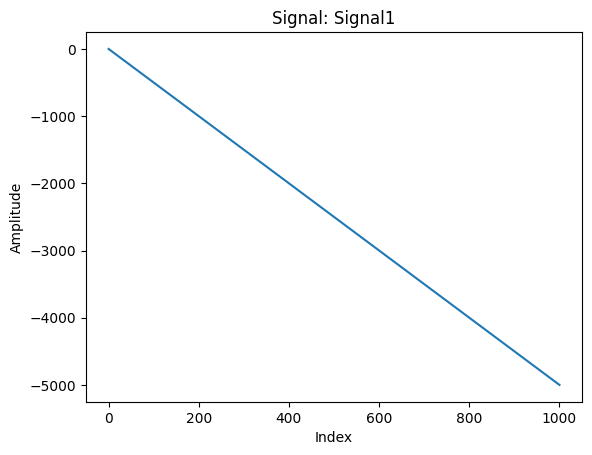

In [ ]:
dis_cont("Signal1", signals)